# Super Typhoon Bavi — Real-Time Forecast (Jul 3 init)

**Init:** 2026-07-03 00Z · **Horizon:** 192 h (8 days, 6-hourly) to landfall · **Target:** Wenzhou, China (28.0 N, 120.7 E), landfall expected ~Jul 11 00Z

An earlier-lead-time companion to the Jul 6 12Z Bavi forecast, initialized sooner and extended
out to the expected landfall time itself. Slimmed to three figures, all from one **ECMWF IFS
operational analysis**:

- **Track** — AIFS2 driven into the **`TCTrackerWuDuan`** cyclone tracker, with daily info
  callouts (min MSLP / max wind / trailing-24h precip) that never overlap.
- **Peak & landfall 10 m wind**, and **24h precip to landfall** — AIFS2 vs GraphCast (operational).

No ERA5/best-track ground truth exists yet (future-valid), so these are forecast products, not skill scores.

In [1]:
# Environment — MUST run before importing torch / jax
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # reduce VRAM fragmentation
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"               # let JAX (GraphCast) share GPU with torch
os.environ["CUFILE_ENV_PATH_JSON"] = "/dev/null"                    # silence cuFile/GDS warnings
os.environ.setdefault("EARTH2STUDIO_CACHE", os.path.expanduser("~/.cache/earth2studio"))

'/home/jovyan/.cache/earth2studio'

In [2]:
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from tqdm.auto import tqdm

from earth2studio.models.px import AIFS2, GraphCastOperational
from earth2studio.models.dx import TCTrackerWuDuan
from earth2studio.data import IFS, fetch_data
from earth2studio.utils.coords import map_coords
from earth2studio.utils.time import to_time_array
import earth2studio.run as run
from earth2studio.io import ZarrBackend

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, torch.cuda.get_device_name() if torch.cuda.is_available() else "")

/home/jovyan/Bavi/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


/home/jovyan/Bavi/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Warp DeprecationWarning: The symbol `warp.context.Device` will soon be removed from the public API. Use `warp.Device` instead.


 parsing error, invalid json config /dev/null
 failed to load user config: /dev/null Invalid argument
 cuFile configuration load error
 cuFile initialization failed
CuPy distance computation test failed with error: cuVS >= 24.12 or pylibraft < 24.12 should be installed to use this feature


device: cuda NVIDIA L40


In [ ]:
# ---- forecast configuration ----
START_TIME = datetime(2026, 7, 3, 0)      # ECMWF IFS analysis cycle
NSTEPS     = 32                            # 192 h / 6 h
STEP_HOURS = 6
LANDFALL   = datetime(2026, 7, 11, 0)      # expected Wenzhou coast arrival

CITIES           = {"Wenzhou": (28.0, 120.7), "Taipei": (25.0, 121.6)}  # name -> (lat, lon)
WENZHOU          = CITIES["Wenzhou"]       # landfall target
STORM_SEARCH_BOX = {"lat": (5.0, 35.0), "lon": (115.0, 150.0)}

# plot extents [lon_min, lon_max, lat_min, lat_max] on the 0-360 grid
TRACK_EXTENT  = [120.0, 150.0, 8.0, 32.0]
PRECIP_EXTENT = [115.0, 150.0, 8.0, 33.0]

MS_TO_KMH = 3.6                                                    # wind unit conversion
PRECIP_LEVELS = [1, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300]     # mm (6-24h accumulation)
# km/h levels from m/s thresholds (gale 17, typhoon 33, ...)
WIND_LEVELS   = [round(v * MS_TO_KMH) for v in (0, 10, 17, 25, 33, 42, 50, 58, 65)]  # km/h
PVARS = np.array(["u10m", "v10m", "tp06"])                          # requested from precip models

PRECIP_CMAP = plt.cm.terrain   # blue -> green -> yellow -> tan -> white

OUT_DIR = Path("outputs/bavi_jul3"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures");           FIG_DIR.mkdir(parents=True, exist_ok=True)

VALID_TIMES = [START_TIME + timedelta(hours=STEP_HOURS * k) for k in range(NSTEPS + 1)]
FCST_WINDOW = f"{VALID_TIMES[0]:%Y-%m-%d} to {VALID_TIMES[-1]:%Y-%m-%d}"

def fig_title(models, when):
    return f"{models} | Init: {START_TIME:%Y-%m-%d %HZ} | {when}"

def mark_cities(ax, cities=CITIES, star_color="red", text_color="black"):
    for name, (lat, lon) in cities.items():
        ax.plot(lon, lat, marker="*", color=star_color, ms=14, transform=ccrs.PlateCarree())
        ax.text(lon + 0.4, lat + 0.4, name, color=text_color, fontsize=9, fontweight="bold",
                ha="left", va="bottom", transform=ccrs.PlateCarree())

print("init:", START_TIME, "-> valid through", VALID_TIMES[-1],
      f"({(LANDFALL - START_TIME).total_seconds()/3600:.0f} h to expected landfall)")

In [ ]:
# one IFS analysis initializes both models; using the AWS archive since this run's init
# is further back than the ~4-day rolling window source="ecmwf" serves
data = IFS(source="aws")

In [5]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1); dlmb = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def path_dataframe(tracks, p):
    lat, lon = tracks[p, :, 0], tracks[p, :, 1]
    df = pd.DataFrame({
        "lead_time_h": np.arange(lat.shape[0]) * STEP_HOURS,
        "tclat": lat, "tclon": lon,
        "tcmsl_hPa": tracks[p, :, 2] / 100.0,   # Pa -> hPa
        "tcw10m_ms": tracks[p, :, 3],
    })
    return df.dropna(subset=["tclat", "tclon"]).reset_index(drop=True)

def select_best_path(tracks):
    # score every detected system: reward time in the search box + track length, penalize
    # final distance from Wenzhou; return the best (score, path index, dataframe).
    box = STORM_SEARCH_BOX
    candidates = []
    for p in range(tracks.shape[0]):
        df = path_dataframe(tracks, p)
        if len(df) < 3:
            continue
        frac_in = (df.tclat.between(*box["lat"]) & df.tclon.between(*box["lon"])).mean()
        d_final = haversine_km(df.tclat.iloc[-1], df.tclon.iloc[-1], *WENZHOU)
        score = 2.0 * frac_in + len(df) / (NSTEPS + 1) - d_final / 2000.0
        candidates.append((score, p, df))
    candidates.sort(key=lambda t: t[0], reverse=True)
    return candidates[0]

In [6]:
# AIFS2 — wind + precip to zarr. Runs sequentially; VRAM freed in finally.
aifs_zarr = str(OUT_DIR / "aifs2_ifs.zarr")
try:
    model = AIFS2.load_model(AIFS2.load_default_package())
    backend = ZarrBackend(aifs_zarr, backend_kwargs={"overwrite": True})
    backend = run.deterministic([START_TIME], NSTEPS, model, data, backend,
                                output_coords={"variable": PVARS}, device=DEVICE)
    print("AIFS2 tp06 shape:", np.asarray(backend["tp06"]).shape)
finally:
    try:
        del model
    except NameError:
        pass
    torch.cuda.empty_cache()

2026-07-10 17:35:38.613 | INFO     | earth2studio.run:deterministic:87 - Running simple workflow!
2026-07-10 17:35:38.613 | INFO     | earth2studio.run:deterministic:94 - Inference device: cuda


Fetching IFS data:   0%|          | 0/92 [00:00<?, ?it/s]

Fetching IFS data:   1%|          | 1/92 [00:02<04:14,  2.79s/it]

Fetching IFS data: 100%|██████████| 92/92 [00:02<00:00, 32.95it/s]

Fetching IFS data:   0%|          | 0/92 [00:00<?, ?it/s]

Fetching IFS data:   1%|          | 1/92 [00:02<04:05,  2.70s/it]

... (34 outputs left out)

Running inference:  97%|█████████▋| 32/33 [00:28<00:00,  1.10it/s]

Running inference: 100%|██████████| 33/33 [00:29<00:00,  1.10it/s]

Running inference: 100%|██████████| 33/33 [00:29<00:00,  1.11it/s]

2026-07-10 17:36:16.350 | SUCCESS  | earth2studio.run:deterministic:191 - 
Inference complete
AIFS2 tp06 shape: (1, 33, 721, 1440)


In [ ]:
# AIFS2 -> TCTrackerWuDuan (721 grid, so map_coords subselects with no regrid)
tracker    = TCTrackerWuDuan()
prognostic = AIFS2.load_model(AIFS2.load_default_package()).to(DEVICE)
tracker.reset_path_buffer()

x, coords = fetch_data(
    source=data,
    time=to_time_array([START_TIME]),
    variable=prognostic.input_coords()["variable"],
    lead_time=prognostic.input_coords()["lead_time"],
    device=DEVICE,
)

output = None
for step, (x, coords) in enumerate(
    tqdm(prognostic.create_iterator(x, coords), total=NSTEPS + 1, desc="AIFS2+tracker")
):
    x, coords = map_coords(x, coords, tracker.input_coords())
    output, output_coords = tracker(x, coords)
    if step == NSTEPS:
        break

tracks_aifs = np.squeeze(output.cpu().numpy())
if tracks_aifs.ndim == 2:            # single detected path -> [step, var]; restore the path axis
    tracks_aifs = tracks_aifs[None]
torch.save(output.cpu(), OUT_DIR / "track_aifs2.pt")
del prognostic
torch.cuda.empty_cache()
print("AIFS2 tracks shape:", tracks_aifs.shape)

In [ ]:
score_a, best_pa, track_aifs_df = select_best_path(tracks_aifs)
# AIFS2 zero-fills msl at step 0 -> NaN it out (daily boxes skip step 0 anyway)
track_aifs_df.loc[track_aifs_df.lead_time_h == 0, "tcmsl_hPa"] = np.nan
print(f"AIFS2: selected path {best_pa} of {tracks_aifs.shape[0]} detected  "
      f"(score {score_a:.2f}, {len(track_aifs_df)} points)")
track_aifs_df.set_index("lead_time_h").to_xarray().to_netcdf(OUT_DIR / "track_aifs2.nc")

In [9]:
# GraphCast (operational) — wind + precip to zarr.
gc_zarr = str(OUT_DIR / "graphcast_ifs.zarr")
try:
    model = GraphCastOperational.load_model(GraphCastOperational.load_default_package())
    backend = ZarrBackend(gc_zarr, backend_kwargs={"overwrite": True})
    backend = run.deterministic([START_TIME], NSTEPS, model, data, backend,
                                output_coords={"variable": PVARS}, device=DEVICE)
    print("GraphCast tp06 shape:", np.asarray(backend["tp06"]).shape)
finally:
    try:
        del model
    except NameError:
        pass
    torch.cuda.empty_cache()

2026-07-10 17:37:16.799 | INFO     | earth2studio.run:deterministic:87 - Running simple workflow!
2026-07-10 17:37:16.800 | INFO     | earth2studio.run:deterministic:94 - Inference device: cuda


Fetching IFS data:   0%|          | 0/82 [00:00<?, ?it/s]

Fetching IFS data:   1%|          | 1/82 [00:02<03:12,  2.38s/it]

Fetching IFS data: 100%|██████████| 82/82 [00:02<00:00, 34.43it/s]

Fetching IFS data:   0%|          | 0/82 [00:00<?, ?it/s]

Fetching IFS data:   1%|          | 1/82 [00:02<03:12,  2.38s/it]

... (36 outputs left out)

Running inference:  97%|█████████▋| 32/33 [05:04<00:01,  1.48s/it]

Running inference: 100%|██████████| 33/33 [05:05<00:00,  1.49s/it]

Running inference: 100%|██████████| 33/33 [05:05<00:00,  9.26s/it]

2026-07-10 17:42:28.952 | SUCCESS  | earth2studio.run:deterministic:191 - 
Inference complete
GraphCast tp06 shape: (1, 33, 721, 1440)


In [ ]:
def open_forecast(zarr_path):
    ds = xr.open_zarr(zarr_path)
    if "time" in ds.dims:
        ds = ds.isel(time=0)          # drop singleton init dim -> (lead_time, lat, lon)
    return ds

def precip_window_mm(ds, end_step, n_steps):
    # sum the n_steps trailing 6-h tp06 accumulations ending at end_step (step 0 isn't one)
    total = ds["tp06"].isel(lead_time=slice(end_step - n_steps + 1, end_step + 1)).sum("lead_time")
    return np.clip(np.asarray(total) * 1000.0, 0, None)

def wind_speed(ds):
    return np.hypot(np.asarray(ds["u10m"]), np.asarray(ds["v10m"])) * MS_TO_KMH  # km/h (lead, lat, lon)

def wind_at(wspd, when):
    s = int(round((when - START_TIME).total_seconds() / 3600 / STEP_HOURS))
    s = min(max(s, 0), NSTEPS)
    return wspd[s]

def domain_max(field2d):
    # peak value within the plotted extent (ignores systems outside the box)
    iy = (LAT >= PRECIP_EXTENT[2]) & (LAT <= PRECIP_EXTENT[3])
    ix = (LON >= PRECIP_EXTENT[0]) & (LON <= PRECIP_EXTENT[1])
    return float(np.nanmax(field2d[np.ix_(iy, ix)]))

def plot_comparison(fieldA, fieldG, lon, lat, levels, cmap, title, save,
                    extent=PRECIP_EXTENT, cbar_label="mm"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6),
                             subplot_kw={"projection": ccrs.PlateCarree()})
    for ax, field, name in zip(axes, [fieldA, fieldG], ["AIFS2", "GraphCast"]):
        # extend="both": no gaps below/above levels, triangle end-caps (forecast-style)
        im = ax.contourf(lon, lat, field, levels=levels, cmap=cmap,
                         transform=ccrs.PlateCarree(), extend="both")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.4)
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)
        mark_cities(ax)
        ax.set_title(name)
        cb = fig.colorbar(im, ax=ax, orientation="horizontal",
                          fraction=0.046, pad=0.06)
        cb.set_label(cbar_label)
    fig.suptitle(title, y=1.02, fontsize=13)
    fig.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()

dsA = open_forecast(str(OUT_DIR / "aifs2_ifs.zarr"))
dsG = open_forecast(str(OUT_DIR / "graphcast_ifs.zarr"))
LON = np.asarray(dsA["lon"]); LAT = np.asarray(dsA["lat"])

WSPD_A, WSPD_G = wind_speed(dsA), wind_speed(dsG)   # km/h (lead, lat, lon), computed once and reused
peakA, peakG = WSPD_A.max(axis=0), WSPD_G.max(axis=0)   # peak 10 m wind (km/h), reused by box + wind plots
print("grid:", LON.shape, LAT.shape, "lon", float(LON.min()), float(LON.max()))

In [ ]:
fig = plt.figure(figsize=(11, 11))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(TRACK_EXTENT, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)

ax.plot(track_aifs_df.tclon, track_aifs_df.tclat, "-o", color="red", lw=2.0, ms=3,
        transform=ccrs.PlateCarree())

# one callout per day (00Z marker): peak intensity + trailing 24h precip at the storm center,
# offset to a fixed (ocean) side of the heading; overlaps resolved by growing the leader length
day_of = np.array([(START_TIME + timedelta(hours=int(h))).date() for h in track_aifs_df.lead_time_h])
lons = track_aifs_df.tclon.values; lats = track_aifs_df.tclat.values; n = len(track_aifs_df)
transform = ccrs.PlateCarree()._as_mpl_transform(ax)
fig.canvas.draw()  # one full draw so the renderer exists and static features are rendered
renderer = fig.canvas.get_renderer()

R0, R_STEP, MAX_TRIES = 46, 20, 10   # base leader length / growth step (points) / max attempts
placed_bboxes = []

def place_box(xy, label, ux, uy):
    # grow the leader length until the box clears every placed box (redraw only this annotation)
    ann = None
    for attempt in range(MAX_TRIES):
        if ann is not None:
            ann.remove()
        R = R0 + attempt * R_STEP
        dx, dy = ux * R, uy * R
        ann = ax.annotate(
            label, xy=xy, xycoords=transform,
            xytext=(dx, dy), textcoords="offset points",
            fontsize=6, ha="left" if dx >= 0 else "right",
            va="bottom" if dy >= 0 else "top", annotation_clip=False,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", lw=0.6),
            arrowprops=dict(arrowstyle="-", color="black", lw=0.6),
        )
        ann.draw(renderer)
        bbox = ann.get_window_extent(renderer=renderer)
        if not any(bbox.overlaps(pb) for pb in placed_bboxes):
            break
    placed_bboxes.append(bbox)

for idx, (_, r) in enumerate(track_aifs_df.iterrows()):
    valid = START_TIME + timedelta(hours=int(r.lead_time_h))
    if valid.hour != 0:                        # daily cadence: anchor at 00Z markers only
        continue
    day = valid.date()
    day_rows = track_aifs_df[day_of == day]
    mslp_min = day_rows.tcmsl_hPa.min()
    wind_max = day_rows.tcw10m_ms.max() * MS_TO_KMH
    s = int(r.lead_time_h // STEP_HOURS)
    if s == 0:
        p_day = 0.0   # no accumulation yet at the initial step
    else:
        field = precip_window_mm(dsA, s, 4)   # trailing 24h precip ending at this 00Z marker
        iy = int(np.abs(LAT - r.tclat).argmin()); ix = int(np.abs(LON - r.tclon).argmin())
        p_day = float(field[iy, ix])
    label = f"{valid:%-m/%-d}\n{mslp_min:.0f} hPa\n{wind_max:.0f} km/h\n{p_day:.0f} mm/24h"

    a = max(idx - 1, 0); b = min(idx + 1, n - 1)
    hx = lons[b] - lons[a]; hy = lats[b] - lats[a]
    px, py = hy, -hx                           # right-hand perpendicular to the heading (fixed side)
    nrm = (px * px + py * py) ** 0.5 or 1.0
    place_box((r.tclon, r.tclat), label, px / nrm, py / nrm)
mark_cities(ax)

ax.set_title(fig_title("AIFS2", FCST_WINDOW) + "  ·  track (daily peak)")
fig.savefig(FIG_DIR / "track_aifs_jul3.png", dpi=150, bbox_inches="tight")
plt.show()

peak 10 m wind: 2026-07-09 (114 km/h)


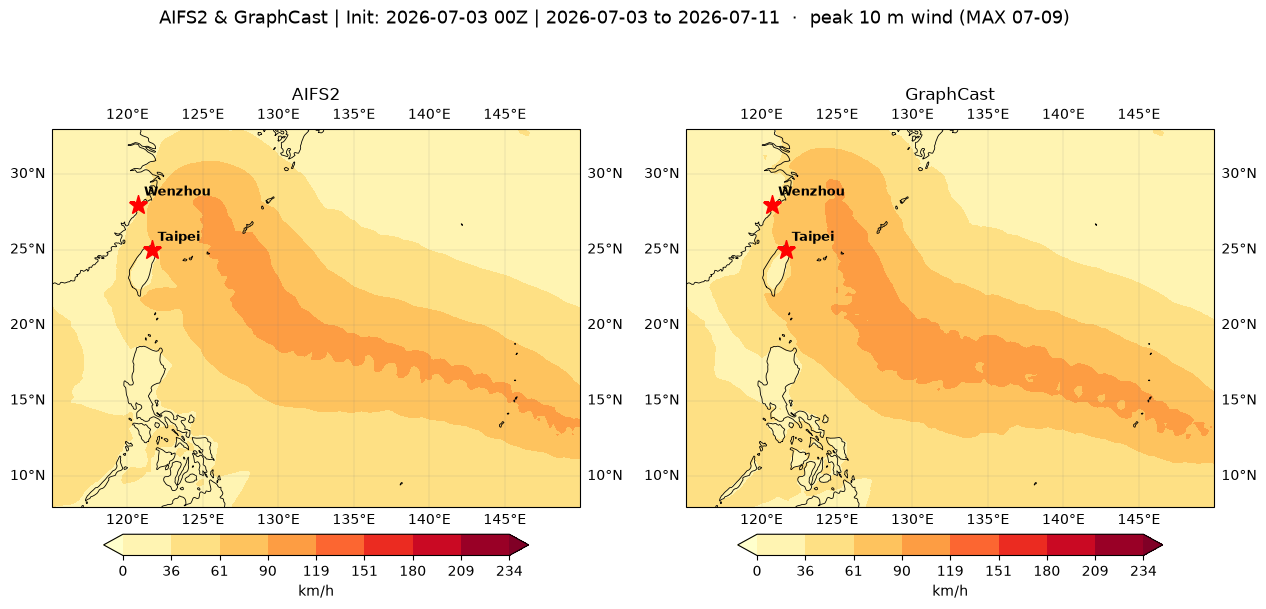

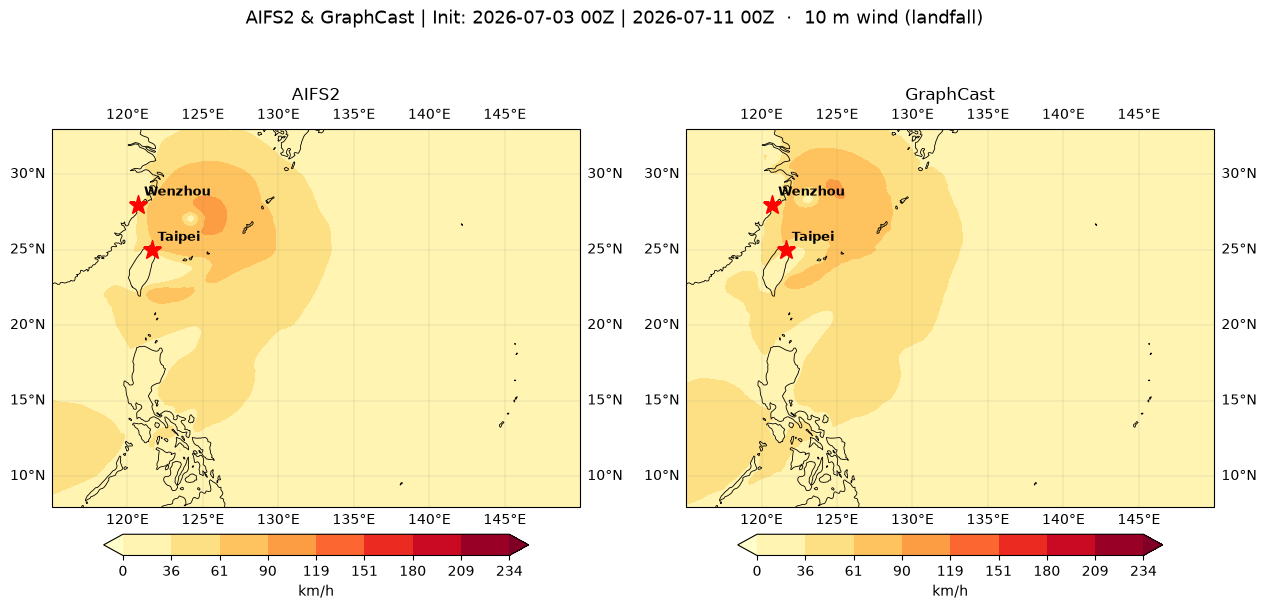

In [12]:
# day of the domain-peak 10 m wind (either model) -> flag it in the peak-wind figure name
def stepwise_domain_peak(wspd):
    return np.array([domain_max(wspd[s]) for s in range(wspd.shape[0])])
sp = np.maximum(stepwise_domain_peak(WSPD_A), stepwise_domain_peak(WSPD_G))
peak_wind_day = VALID_TIMES[int(np.argmax(sp))].date()
print("peak 10 m wind:", peak_wind_day, f"({sp.max():.0f} km/h)")

plot_comparison(peakA, peakG, LON, LAT, WIND_LEVELS, plt.cm.YlOrRd,
                fig_title("AIFS2 & GraphCast", FCST_WINDOW) + f"  ·  peak 10 m wind (MAX {peak_wind_day:%m-%d})",
                FIG_DIR / f"wind_peak_jul3_{peak_wind_day}_max.png", cbar_label="km/h")

plot_comparison(wind_at(WSPD_A, LANDFALL), wind_at(WSPD_G, LANDFALL), LON, LAT, WIND_LEVELS, plt.cm.YlOrRd,
                fig_title("AIFS2 & GraphCast", f"{LANDFALL:%Y-%m-%d %HZ}") + "  ·  10 m wind (landfall)",
                FIG_DIR / "wind_landfall_jul3.png", cbar_label="km/h")

In [ ]:
# 24h precip ending at landfall (sum of 4 trailing 6h steps, not a single slice or storm-total)
precipA_lf = precip_window_mm(dsA, NSTEPS, 4)
precipG_lf = precip_window_mm(dsG, NSTEPS, 4)
plot_comparison(precipA_lf, precipG_lf, LON, LAT, PRECIP_LEVELS, PRECIP_CMAP,
                fig_title("AIFS2 & GraphCast", f"{LANDFALL:%Y-%m-%d %HZ}") + "  ·  24h precip to landfall",
                FIG_DIR / "precip_landfall_jul3.png", cbar_label="mm")

## Method notes
- Precip is `tp06` (6-h accumulation, metres → mm ×1000, step 0 skipped); wind is √(u10m²+v10m²).
- Forecast is future-valid — verify against IBTrACS best-track / ERA5 once available.